# 9-1. d 고정 -- 자동 선택이 안 되는 이유와 데이터 특징 기반 결정

**전체 계획** (auto_arima만 사용, GARCH/SV는 나중에)

1. **d 고정** (이 노트북)
2. auto_arima로 p,q 선택 (AIC vs AICc)
3. 원 스케일: 리샘플링 vs 자체 7분위 비교
4. 로그 스케일: 리샘플링 vs 자체 7분위 비교

**공통 조건**: CRPS는 모델 자체 구간의 7분위(10·20·30·50·70·80·90%)로 계산한다.

**흐름**: (1) d를 자동으로 정하면 안 되는 이유 -> (2) 데이터 특징으로 d=1 설정 -> (3) d=0, 1, 2 성능 확인(결정에는 쓰지 않음).

**origin 표기**: `origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)`처럼 훈련·예측 기간을 함께 적는다.

## 0. 데이터와 평가 방법

이 시리즈(9-1~9-4) 전체에 공통으로 쓰는 데이터와 평가 방식이다.

### 데이터

| 변수명 | 변수 한글명 | 정의 | 기간 / 크기 |
|---|---|---|---|
| `X3_l1` | X3(1분기 전) | X3의 최근 4분기 합계를 1분기 지연한 값 (`rolling(4).sum()`) | 2011Q1 ~ 2025Q4, 분기 60개 |

- 주요변수 한 개를 선정해서 사용한다(프로젝트의 금 수요 요인 변수 6개 중 'X3').
- 별도 전처리 없이 수준 y 그대로 사용한다(로그 비교에서만 `100 x log y`).
- 4분기 합계라서 연속한 분기 값이 기계적으로 겹쳐 자기상관이 높다.
- 예측 대상은 이 변수의 미래 분기 값(h=1~4분기 후)이다.

### 평가 설정 (walk-forward)

- **expanding window**: 훈련 20분기에서 시작해 origin마다 한 분기씩 확장하며 h=1~4를 예측한다. 처음 15개 origin은 리샘플링 캘리브레이션에 쓰고, 이후 **22개 origin**(origin 35~56, 예측 2019Q4~2025Q4)을 채점한다(22 x 4 = 88개 예측).
- **자체 구간** = 모델의 정규분포 구간, **리샘플링 구간** = 과거 h단계 예측오차 500개를 복원추출해 점예측에 더한 분포.
- **모델**: `auto_arima`(d=1 고정, p,q는 AICc로 선택, 나머지 기본값). 이후 모든 비교의 점예측은 이 모델이다.
- 모든 예측은 그 시점까지의 데이터로만 학습한다.

| origin | 훈련 기간 | 예측 기간 |
|---|---|---|
| 35 (첫 채점) | 2011Q1 ~ 2019Q3 | 2019Q4 ~ 2020Q3 |
| 56 (마지막) | 2011Q1 ~ 2024Q4 | 2025Q1 ~ 2025Q4 |

### 평가 지표

모든 지표는 22개 origin x h=1~4 = 88개 예측의 평균이며, `var_std`(전체 표준편차)로 정규화한다.

**1. CRPS(7분위)** -- 분위수를 α로 나눠서 만든다

| α | 중앙 구간 | 하한 분위 | 상한 분위 |
|---|---|---|---|
| 0.2 | 80% 구간 | 10% | 90% |
| 0.4 | 60% 구간 | 20% | 80% |
| 0.6 | 40% 구간 | 30% | 70% |
| -- | 점예측(중앙값) | 50% | 50% |

- α 구간 [하한, 상한]에서 분위수 7개(10·20·30·50·70·80·90%)를 얻는다.
- 자체 구간: `predict`의 `conf_int(alpha=0.2, 0.4, 0.6)` / 리샘플링: 표본 500개의 분위수.
- CRPS = 7개 분위수의 pinball loss 평균 x 2 (CRPS의 분위수 근사), `var_std`로 정규화. h=1~4 평균 후 origin 평균(낮을수록 좋음).

**2. MSE**: `((실제 - 점예측) / var_std)²`의 평균(88개). 두 구간 방식이 같은 점예측을 공유하므로 같은 값이다.

**3. 커버리지**(목표 90%): 90% 구간(α=0.10)에 실제값이 들어간 비율. 자체 구간은 `conf_int(alpha=0.10)`, 리샘플링 구간은 표본 500개의 5%~95% 분위수를 쓴다. 들어가면 1, 아니면 0으로 88개를 평균한다.


In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
from pmdarima.arima import ndiffs
import properscoring as ps
from scipy import stats
from statsmodels.tsa.stattools import kpss, adfuller, acf

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
quarters, vals = data["quarter"].values, data["X3_l1"].values.astype(float)
var_std = vals.std()
scored_origins = list(range(MIN_TRAIN, len(vals) - H + 1))[INITIAL_CALIB:]
FIRST = scored_origins[0]


def label(o):
    return f"origin {o} (훈련 {quarters[0]}~{quarters[o - 1]}, 예측 {quarters[o]}~{quarters[o + H - 1]})"


def period(o):
    return pd.Series({"훈련 기간": f"{quarters[0]}~{quarters[o - 1]}", "예측 기간": f"{quarters[o]}~{quarters[o + H - 1]}"})


print(f"전체 {len(vals)}분기 ({quarters[0]}~{quarters[-1]}), 채점 origin {len(scored_origins)}개")
print("첫 origin:", label(FIRST))
print("마지막 origin:", label(scored_origins[-1]))


전체 60분기 (2011Q1~2025Q4), 채점 origin 22개
첫 origin: origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)
마지막 origin: origin 56 (훈련 2011Q1~2024Q4, 예측 2025Q1~2025Q4)


## 1. d를 자동으로 정하면 안 되는 이유

### 1-1. 단위근 검정 결과가 origin마다 일관되지 않다

`auto_arima`는 d를 **단위근 검정**으로 먼저 정하고, 그 d 안에서 p,q를 AIC로 고른다. 각 origin의 훈련 데이터로 두 검정을 돌려 본다.

유의수준 0.05 기준으로 읽는다.

| 검정 | 귀무가설 | p < 0.05 | p ≥ 0.05 |
|---|---|---|---|
| KPSS | 정상이다 | 정상을 기각 -> **차분이 필요** | 기각 못함 -> 차분이 필요하다는 증거 없음 |
| ADF | 단위근이다 | 단위근을 기각 -> **(차분한) 데이터가 정상** | 기각 못함 -> **차분 필요** |

- 예: KPSS p=0.02는 차분이 필요하다는 신호, ADF p=0.002는 정상이라는 신호다.
- p가 크다는 것은 증거가 없다는 뜻이지 반대 결론이 증명된 것은 아니다. 표본이 작으면 p가 크게 나오기 쉬워서 그 자체를 결론으로 삼지 않는다.
- statsmodels의 KPSS p-value는 0.01~0.10 범위로 잘려서 나온다(0.10이면 "0.10 이상").

In [2]:
rows = []
for o in scored_origins:
    train = vals[:o]
    _, kp, _, _ = kpss(train, regression="c", nlags="auto")
    adf_p = adfuller(train, regression="c")[1]
    rows.append({"origin": o, **period(o), "n": len(train), "KPSS p": kp, "ADF p": adf_p,
                 "d(KPSS)": ndiffs(train, test="kpss"), "d(ADF)": ndiffs(train, test="adf")})
dtab = pd.DataFrame(rows).set_index("origin")
display(dtab.round(3))
print("KPSS p가 상한(0.10)에 붙은 origin:", int((dtab["KPSS p"] >= 0.099).sum()), "/", len(dtab))
print("d 선택 분포 -- KPSS:", dtab["d(KPSS)"].value_counts().sort_index().to_dict(), " ADF:", dtab["d(ADF)"].value_counts().sort_index().to_dict())
print("두 검정이 다른 d를 고른 origin:", int((dtab["d(KPSS)"] != dtab["d(ADF)"]).sum()), "/", len(dtab))


C:\Users\Administrator\AppData\Local\Temp\ipykernel_16156\191061376.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  _, kp, _, _ = kpss(train, regression="c", nlags="auto")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_16156\191061376.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  _, kp, _, _ = kpss(train, regression="c", nlags="auto")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_16156\191061376.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  _, kp, _, _ = kpss(train, regression="c", nlags="auto")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_16156\191061376.py:4: InterpolationWarning: The tes

C:\Users\Administrator\AppData\Local\Temp\ipykernel_16156\191061376.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  _, kp, _, _ = kpss(train, regression="c", nlags="auto")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_16156\191061376.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  _, kp, _, _ = kpss(train, regression="c", nlags="auto")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_16156\191061376.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  _, kp, _, _ = kpss(train, regression="c", nlags="auto")


,훈련 기간,예측 기간,n,KPSS p,ADF p,d(KPSS),d(ADF)
origin,,,,,,,
35,2011Q1~2019Q3,2019Q4~2020Q3,35,0.100,0.413,0,2
36,2011Q1~2019Q4,2020Q1~2020Q4,36,0.100,0.043,0,2
37,2011Q1~2020Q1,2020Q2~2021Q1,37,0.100,0.037,0,2
38,2011Q1~2020Q2,2020Q3~2021Q2,38,0.100,0.038,0,2
39,2011Q1~2020Q3,2020Q4~2021Q3,39,0.100,0.425,0,2
40,2011Q1~2020Q4,2021Q1~2021Q4,40,0.100,0.438,0,2
41,2011Q1~2021Q1,2021Q2~2022Q1,41,0.100,0.425,0,2
42,2011Q1~2021Q2,2021Q3~2022Q2,42,0.100,0.014,0,2
43,2011Q1~2021Q3,2021Q4~2022Q3,43,0.100,0.351,0,0


KPSS p가 상한(0.10)에 붙은 origin: 20 / 22
d 선택 분포 -- KPSS: {0: 21, 1: 1}  ADF: {0: 3, 1: 7, 2: 12}
두 검정이 다른 d를 고른 origin: 18 / 22


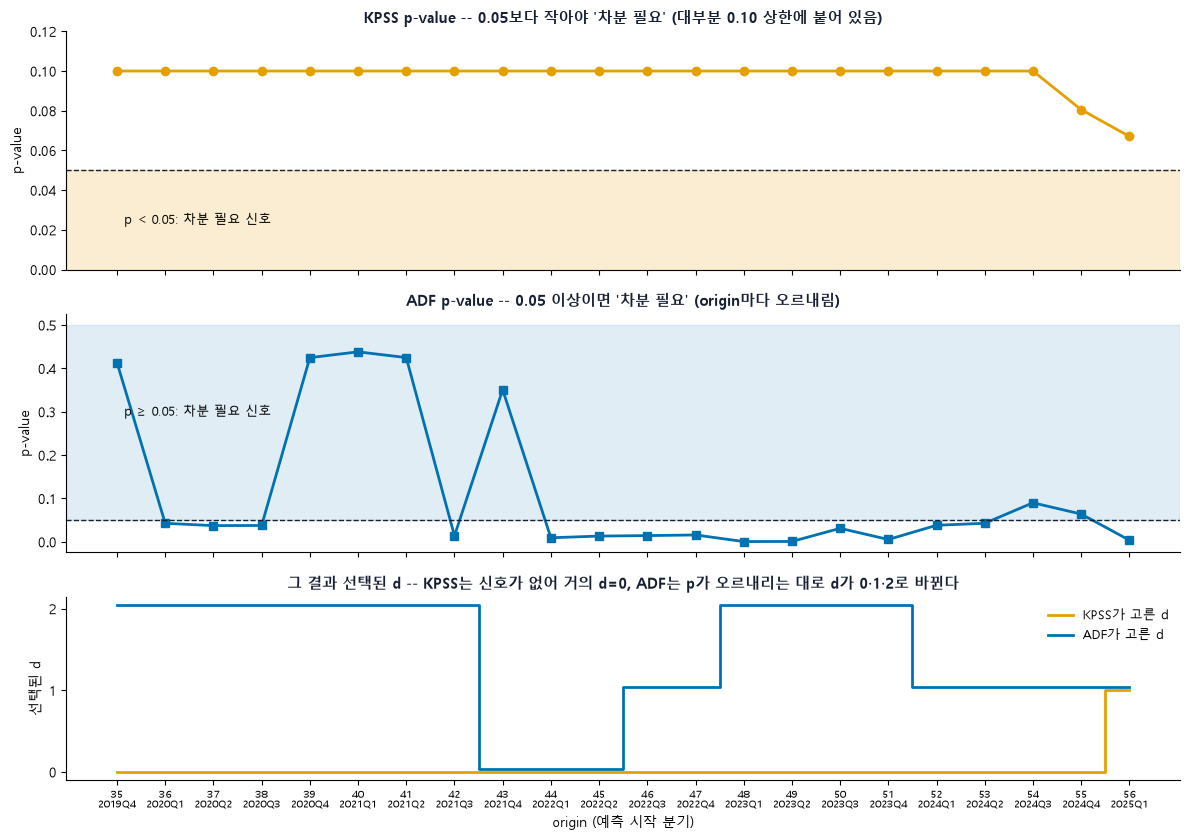

In [3]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

xl = [f"{o}\n{quarters[o]}" for o in dtab.index]
xx = np.arange(len(dtab))
fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1.3, 1]})

# (1) KPSS p-value: 0.05보다 작으면 차분 필요
axes[0].axhspan(0, 0.05, color="#E69F00", alpha=0.18)
axes[0].plot(xx, dtab["KPSS p"], marker="o", color="#E69F00", linewidth=2)
axes[0].axhline(0.05, color="#172033", linestyle="--", linewidth=1)
axes[0].set_ylim(0, 0.12)
axes[0].text(0.15, 0.025, "p < 0.05: 차분 필요 신호", fontsize=9, va="center")
axes[0].set_title("KPSS p-value -- 0.05보다 작아야 '차분 필요' (대부분 0.10 상한에 붙어 있음)", fontsize=11, fontweight="bold", color="#172033")

# (2) ADF p-value: 0.05 이상이면 차분 필요
axes[1].axhspan(0.05, 0.5, color="#0072B2", alpha=0.12)
axes[1].plot(xx, dtab["ADF p"], marker="s", color="#0072B2", linewidth=2)
axes[1].axhline(0.05, color="#172033", linestyle="--", linewidth=1)
axes[1].text(0.15, 0.30, "p ≥ 0.05: 차분 필요 신호", fontsize=9, va="center")
axes[1].set_title("ADF p-value -- 0.05 이상이면 '차분 필요' (origin마다 오르내림)", fontsize=11, fontweight="bold", color="#172033")

# (3) 그 결과 선택된 d
axes[2].step(xx, dtab["d(KPSS)"], where="mid", color="#E69F00", linewidth=2, label="KPSS가 고른 d")
axes[2].step(xx, dtab["d(ADF)"] + 0.04, where="mid", color="#0072B2", linewidth=2, label="ADF가 고른 d")
axes[2].set_yticks([0, 1, 2])
axes[2].set_ylabel("선택된 d")
axes[2].legend(frameon=False, loc="upper right", fontsize=9)
axes[2].set_title("그 결과 선택된 d -- KPSS는 신호가 없어 거의 d=0, ADF는 p가 오르내리는 대로 d가 0·1·2로 바뀐다", fontsize=11, fontweight="bold", color="#172033")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].set_ylabel("p-value")
axes[1].set_ylabel("p-value")
axes[2].set_xticks(xx)
axes[2].set_xticklabels(xl, fontsize=7)
axes[2].set_xlabel("origin (예측 시작 분기)")
fig.tight_layout()
plt.show()


**그림에서 보이는 것**

- **KPSS**: p-value가 대부분 상한 0.10에 붙어 '차분 필요' 신호(p < 0.05)가 한 번도 나오지 않는다. 그래서 d=0이 21개다. 흔들린다기보다 **정보가 없다**.
- **ADF**: p-value가 0.01~0.44를 오가고 d가 2·0·1·2·1로 바뀐다.
- **두 검정**이 다른 d를 고른 origin이 18/22개다.
- 훈련 데이터가 한 분기씩 늘어나는 것이므로 결과가 바뀐다고 검정이 틀렸다는 증거는 아니다. 이 그림이 보여 주는 것은 **자동 선택의 결과가 일관되지 않다**는 데까지다.

### 1-2. AIC·AICc로는 d를 비교할 수 없다

AIC·AICc는 **같은 데이터의 우도**끼리만 비교할 수 있다. d가 다르면 설명하는 데이터가 다르다(수준 y vs 차분 Δy). 같은 훈련 데이터에 d=0과 d=1 모델의 AIC를 놓고 확인한다.

단, **예측 성능**(MSE, CRPS, 커버리지)은 d가 달라도 비교할 수 있다. d=1 모델은 차분을 예측하지만 마지막 값에서 누적해 **수준 y의 예측**으로 되돌리고, 실제 수준 y와 비교하기 때문이다(3절).


In [4]:
aic_rows = []
for o in [FIRST, scored_origins[len(scored_origins) // 2], scored_origins[-1]]:
    train = vals[:o]
    r = {"origin": o, **period(o)}
    for d in [0, 1]:
        m = pm.ARIMA(order=(1, d, 0), with_intercept=(d == 0), suppress_warnings=True).fit(train)
        r[f"AIC(d={d})"] = m.aic()
        r[f"AICc(d={d})"] = m.aicc()
    aic_rows.append(r)
display(pd.DataFrame(aic_rows).set_index("origin").round(1))
print("d=0과 d=1의 AIC는 서로 다른 데이터(y vs Δy)의 우도라 크기를 비교할 수 없다.")


,훈련 기간,예측 기간,AIC(d=0),AICc(d=0),AIC(d=1),AICc(d=1)
origin,,,,,,
35,2011Q1~2019Q3,2019Q4~2020Q3,394.8,395.6,367.7,368.1
46,2011Q1~2022Q2,2022Q3~2023Q2,528.1,528.7,503.9,504.2
56,2011Q1~2024Q4,2025Q1~2025Q4,685.6,686.0,654.1,654.3


d=0과 d=1의 AIC는 서로 다른 데이터(y vs Δy)의 우도라 크기를 비교할 수 없다.


### 1-3. 정리

- origin마다 d가 달라지면 **서로 다른 종류의 모델을 섞어 평가**하게 된다(검정이 틀렸다는 증명이 아니라 일관성의 문제).
- AIC·AICc로 d를 대신 고를 수도 없다.
- 그래서 **d는 `auto_arima`에 맡기지 않고 데이터의 특징으로 정해서 고정**한다. d=1이 맞다는 근거는 이 절이 아니라 2절(데이터 특징)과 3절(성능 확인)이다.

## 2. 데이터 특징으로 d를 정한다

`X3_l1`은 X3의 **4분기 합계**(1분기 시차)다. 전체 데이터(2011Q1~2025Q4, 60개)의 그림과 ACF를 본다. d는 성능이 아니라 데이터 자체의 특징으로 정한다.

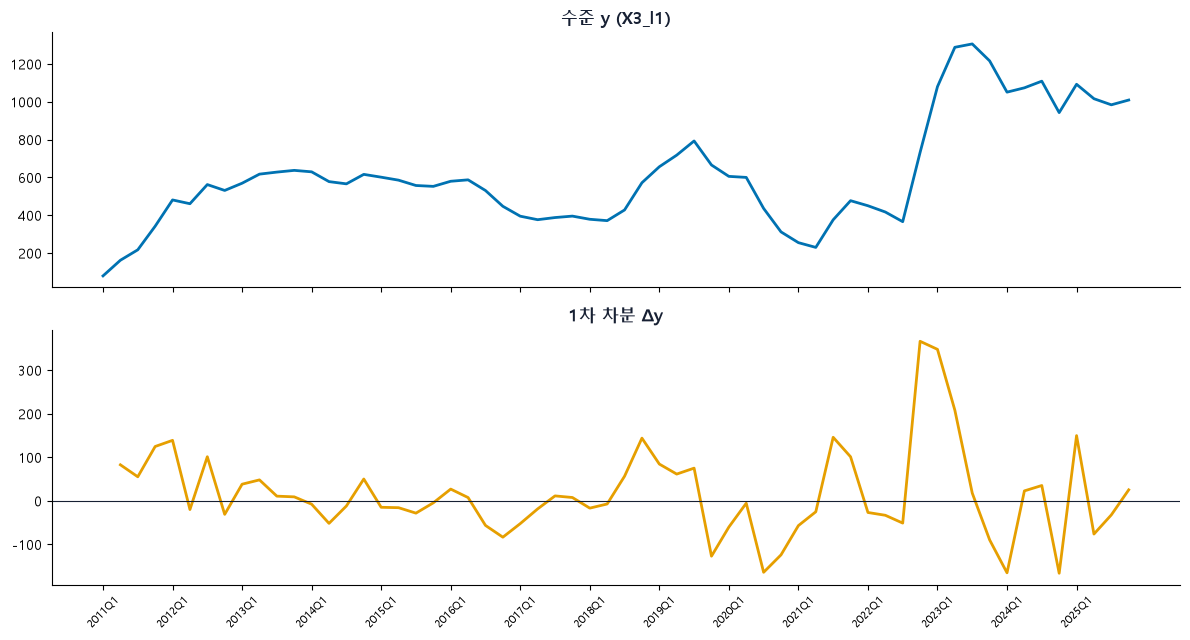

In [5]:
x = np.arange(len(vals))
dy = np.diff(vals)
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(x, vals, color="#0072B2", linewidth=2)
axes[0].set_title("수준 y (X3_l1)", fontsize=12, fontweight="bold", color="#172033")
axes[1].plot(x[1:], dy, color="#E69F00", linewidth=2)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=12, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[1].set_xticks(x[::4])
axes[1].set_xticklabels(quarters[::4], rotation=45, fontsize=8)
fig.tight_layout()
plt.show()


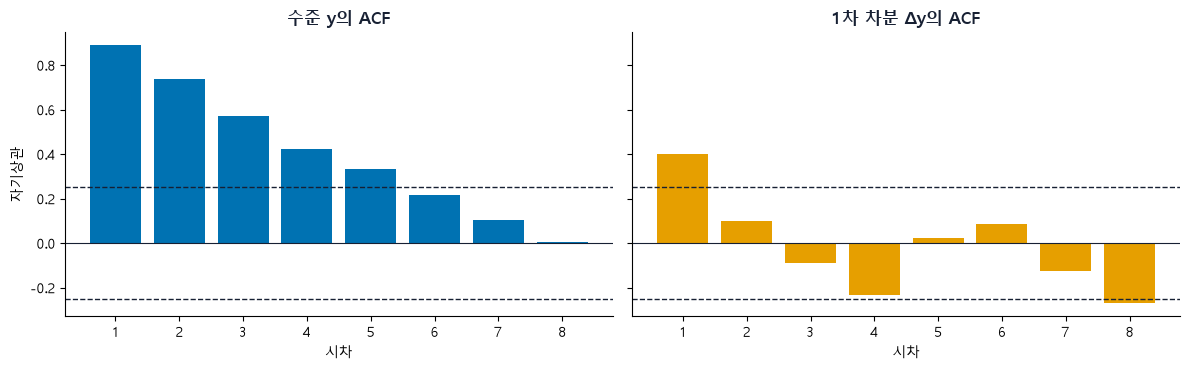

,y,Δy
시차,,
1,0.890,0.402
2,0.737,0.101
3,0.573,-0.091
4,0.425,-0.234
5,0.332,0.021
6,0.218,0.086
7,0.106,-0.127
8,0.006,-0.270


점선: 95% 유의 범위 ±0.25 (표본 60개). lag-1 자기상관 -- 수준 0.89, 차분 0.40


In [6]:
NL = 8
a_y, a_dy = acf(vals, nlags=NL), acf(dy, nlags=NL)
band = 1.96 / np.sqrt(len(vals))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, a, t, c in [(axes[0], a_y, "수준 y의 ACF", "#0072B2"), (axes[1], a_dy, "1차 차분 Δy의 ACF", "#E69F00")]:
    ax.bar(range(1, NL + 1), a[1:], color=c)
    ax.axhline(band, color="#172033", linestyle="--", linewidth=1)
    ax.axhline(-band, color="#172033", linestyle="--", linewidth=1)
    ax.axhline(0, color="#172033", linewidth=0.8)
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.set_xlabel("시차")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].set_ylabel("자기상관")
fig.tight_layout()
plt.show()

display(pd.DataFrame({"y": a_y[1:], "Δy": a_dy[1:]}, index=pd.Index(range(1, NL + 1), name="시차")).round(3))
print(f"점선: 95% 유의 범위 ±{band:.2f} (표본 {len(vals)}개). lag-1 자기상관 -- 수준 {a_y[1]:.2f}, 차분 {a_dy[1]:.2f}")


### d 결정 -- d=1

- **그림**: 수준이 수년 단위로 크게 출렁이며 한 평균 주위에 머물지 않는다.
- **수준의 ACF**: lag-1 0.89, 이후 0.74, 0.57, 0.43, 0.33으로 천천히 줄어든다(단위근의 전형적 모양).
- **차분 후**: lag-1만 0.40이고 나머지는 대부분 ±0.25 안이다. 과차분 신호는 없다.
- **검정(전체 60개)**: 수준은 KPSS p=0.02(차분 필요), ADF p=0.18(단위근 기각 못함). 차분하면 KPSS p=0.10, ADF p=0.002로 정상이다. 모두 d=1과 일치한다.
- **d=2는 필요 없다**: 1차 차분 후 추세가 남아 있지 않다.

**왜 차분(정상화)하는가**: 목표는 자기상관을 없애는 것이 아니라 시계열을 **정상**으로 만드는 것이다. 수준의 ACF가 천천히 줄어드는 것은 정상이 아니라는 신호다.
- 정상이 아니면 AR 모델의 가정(평균과 자기상관 구조가 일정)이 깨져 계수 추정과 AIC를 믿을 수 없다.
- d=0은 예측이 훈련 평균으로 끌려가고 먼 h의 구간이 좁아진다. 이 데이터에서도 d=0의 성능이 나빴다(3절).
- 차분하면 '변화량'을 모델링하므로 예측이 마지막 값에서 변화량을 누적하는 형태가 되고, 구간이 h에 따라 자연스럽게 넓어진다.
- 차분 후 남는 lag-1 0.40은 AR(1)이 모델링한다. 필요 이상으로 차분(d=2)하면 노이즈만 커지므로 정상이 되는 최소한만 차분한다.

d=1은 "계속 오른다"는 뜻이 아니다. 드리프트(상수항)를 넣지 않으므로 예측은 마지막 값 근처를 유지한다. 근거는 "큰 변동이 오래 지속되고 평균으로 돌아오지 않는다"는 것이다.

**주의**: 변수가 4분기 합이라 자기상관이 기계적으로 높다. ACF만이 아니라 그림·차분 후 변화·검정을 함께 근거로 삼았다.

### 참고: 표본에 따라 검정이 달라진다 (한계의 근거)

판단은 평가 구간(점선 오른쪽, origin 35 이후)을 포함한 전체 60개로 했다. 첫 35개(2011Q1~2019Q3)만 쓰면 검정이 어떻게 달라지는지 비교한다.

In [7]:
def tests(y):
    return {"n": len(y), "ACF lag-1": acf(y, nlags=1)[1], "KPSS p": kpss(y, regression="c", nlags="auto")[1],
            "ADF p": adfuller(y, regression="c")[1]}


samp = {"전체 60개": vals, "첫 35개": vals[:FIRST]}
rows = []
for sname, y in samp.items():
    for tname, z in [("수준 y", y), ("차분 Δy", np.diff(y))]:
        rows.append({"표본": sname, "시계열": tname, **tests(z)})
    rows[-2]["ndiffs(KPSS)"] = ndiffs(y, test="kpss")
    rows[-2]["ndiffs(ADF)"] = ndiffs(y, test="adf")
display(pd.DataFrame(rows).set_index(["표본", "시계열"]).round(3))


C:\Users\Administrator\AppData\Local\Temp\ipykernel_16156\2530652527.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  return {"n": len(y), "ACF lag-1": acf(y, nlags=1)[1], "KPSS p": kpss(y, regression="c", nlags="auto")[1],
C:\Users\Administrator\AppData\Local\Temp\ipykernel_16156\2530652527.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  return {"n": len(y), "ACF lag-1": acf(y, nlags=1)[1], "KPSS p": kpss(y, regression="c", nlags="auto")[1],
C:\Users\Administrator\AppData\Local\Temp\ipykernel_16156\2530652527.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  return {"n": len(y), "ACF lag-1": acf(y, nlags=1)[1], "K

n  ACF lag-1  KPSS p  ADF p  ndiffs(KPSS)  ndiffs(ADF)
표본     시계열                                                           
전체 60개 수준 y   60      0.890   0.024  0.184           1.0          1.0
       차분 Δy  59      0.402   0.100  0.002           NaN          NaN
첫 35개  수준 y   35      0.755   0.100  0.413           0.0          2.0
       차분 Δy  34      0.464   0.100  0.605           NaN          NaN

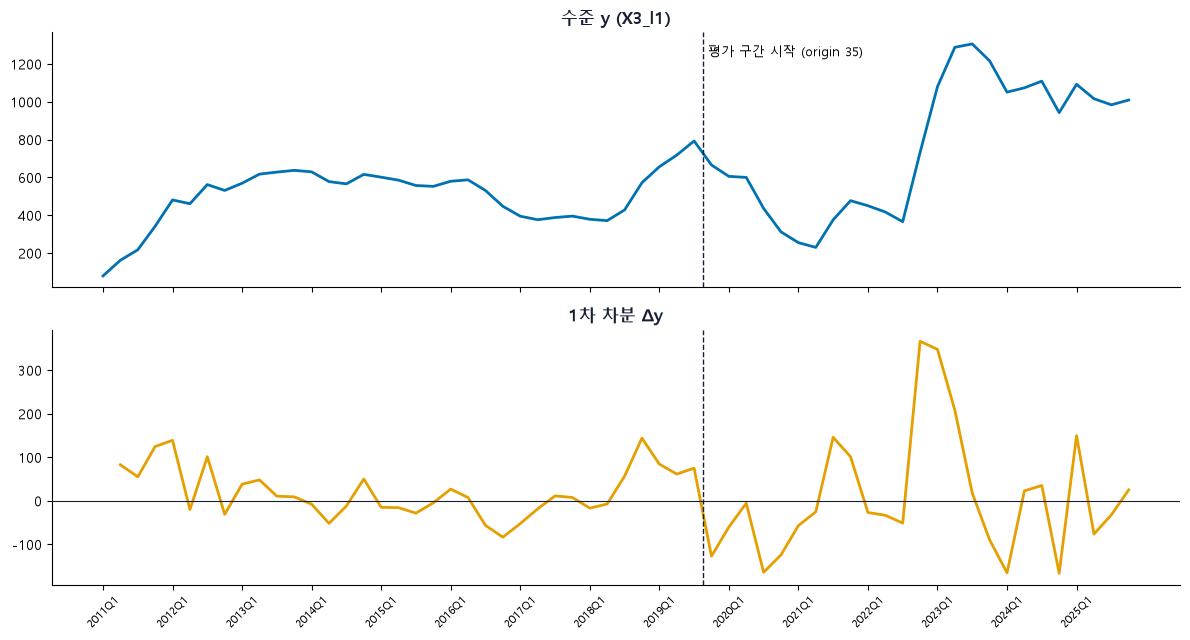

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(x, vals, color="#0072B2", linewidth=2)
axes[0].set_title("수준 y (X3_l1)", fontsize=12, fontweight="bold", color="#172033")
axes[1].plot(x[1:], dy, color="#E69F00", linewidth=2)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=12, fontweight="bold", color="#172033")
for ax in axes:
    ax.axvline(FIRST - 0.5, color="#172033", linestyle="--", linewidth=1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].text(FIRST - 0.2, vals.max() * 0.95, "평가 구간 시작 (origin 35)", ha="left", fontsize=9)
axes[1].set_xticks(x[::4])
axes[1].set_xticklabels(quarters[::4], rotation=45, fontsize=8)
fig.tight_layout()
plt.show()


**왜 달라지나**

- **표본이 작으면 검정력이 낮다**: 첫 35개에서는 KPSS(p=0.10, 상한)와 ADF(p=0.41) 모두 기각하지 못하고, 차분한 Δy도 ADF p=0.61이라 d=2로 나온다.
- **평가 구간에 수준이 크게 이동한다**: 2020~21년 약 800에서 230대로 하락, 2022~23년 약 370에서 1,300으로 급등. 수준이 한 평균에 머물지 않는다는 점이 뚜렷해져 전체에서는 KPSS가 정상을 기각한다(p=0.02).
- 핵심은 단순한 변동성이 아니라 **수준 자체의 큰 이동**이다. 원인을 따로 검증한 것은 아니며, 전체 데이터 기준의 결론이 마지막 구간에 민감하다(KPSS p는 마지막 origin에서야 0.067로 내려옴).

## 3. 확인 -- d=0, 1, 2 성능 비교 (결정 용도가 아님)

d를 고정하고 p,q는 `auto_arima`(AICc, 최대 3)가 고르게 했을 때의 성능이다. **결과가 어떻게 나와도 2절의 결정을 바꾸지 않는다.**

- **CRPS(7분위)**: 모델 구간에서 분위수 10·20·30·50·70·80·90%를 만들고(10~90, 20~80, 30~70%는 `conf_int`, 50%는 점예측), (origin, h)별 `2 x mean(pinball) / var_std`를 h 평균, origin 평균한다. 10% 밖 꼬리는 반영하지 못하는 근사식이다.
- **커버리지**: 90% 구간에 실제값이 들어간 비율. **MSE**: 점예측 오차를 `var_std`로 정규화한 제곱 평균.

In [9]:
LEVELS = np.array([0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9])


def pinball(q, y, tau):
    return np.where(y >= q, (y - q) * tau, (q - y) * (1 - tau))


def quantiles7(m):
    # 모델 자체의 구간: alpha 0.2/0.4/0.6 -> 10~90, 20~80, 30~70%, 50%는 점예측
    fc = m.predict(n_periods=H)
    q = {0.5: fc}
    for alpha in (0.2, 0.4, 0.6):
        _, conf = m.predict(n_periods=H, return_conf_int=True, alpha=alpha)
        q[round(alpha / 2, 1)], q[round(1 - alpha / 2, 1)] = conf[:, 0], conf[:, 1]
    return fc, np.array([q[t] for t in LEVELS])  # (7, H)


def run_fixed_d(d):
    out = []
    for o in scored_origins:
        train, actual = vals[:o], vals[o:o + H]
        m = pm.auto_arima(train, d=d, seasonal=False, information_criterion="aicc", max_p=3, max_q=3,
                          suppress_warnings=True, error_action="ignore")
        fc, q7 = quantiles7(m)
        crps7 = 2 * np.mean([pinball(q7[k], actual, LEVELS[k]) for k in range(7)], axis=0) / var_std  # h별
        _, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
        sig = np.maximum((conf[:, 1] - conf[:, 0]) / (2 * Z), 1e-6)
        out.append({"origin": o, "order": m.order, "커버리지": 100 * np.mean((actual >= conf[:, 0]) & (actual <= conf[:, 1])),
                    "MSE": np.mean(((actual - fc) / var_std) ** 2),
                    "CRPS(7분위)": crps7.mean()})
    return pd.DataFrame(out).set_index("origin")


CACHE = "../cache/cache_91_fixed_d_q7_df.pkl"
if os.path.exists(CACHE):
    fixed = pd.read_pickle(CACHE)
else:
    fixed = pd.concat({d: run_fixed_d(d) for d in [0, 1, 2]}, names=["d"])
    fixed.to_pickle(CACHE)
summary = fixed.groupby("d")[["커버리지", "MSE", "CRPS(7분위)"]].mean().round(3)
display(summary)
print("origin별 선택된 (p,d,q) 분포:")
display(fixed.groupby("d")["order"].value_counts().unstack("d").fillna(0).astype(int))


,커버리지,MSE,CRPS(7분위)
d,,,
0,50.000,1.269,0.681
1,61.364,1.164,0.621
2,43.182,2.495,0.948


origin별 선택된 (p,d,q) 분포:


d,0,1,2
order,,,
"(0, 1, 1)",0,2,0
"(0, 2, 0)",0,0,3
"(0, 2, 1)",0,0,11
"(1, 0, 2)",1,0,0
"(1, 0, 3)",2,0,0
"(1, 1, 0)",0,17,0
"(1, 2, 1)",0,0,3
"(2, 0, 0)",13,0,0
"(2, 0, 1)",6,0,0


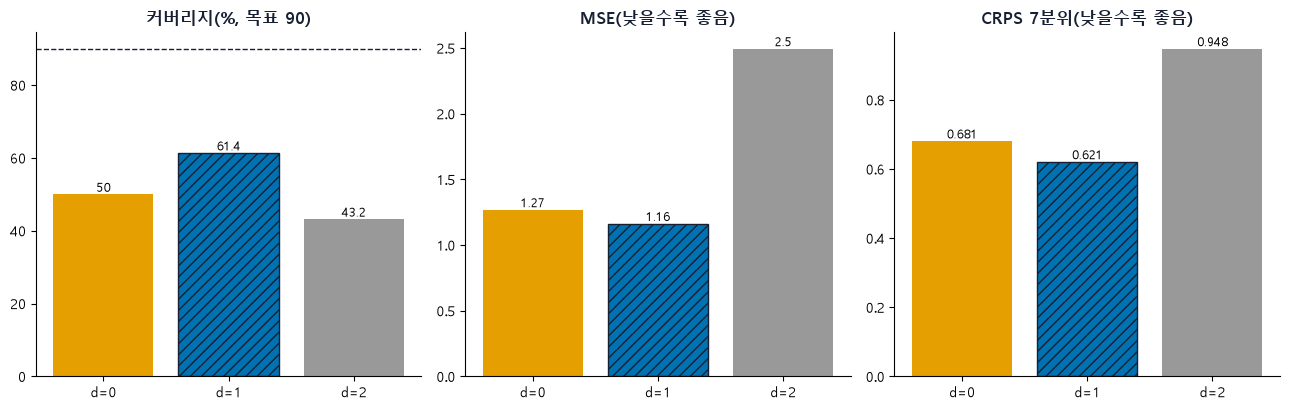

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
cols = {0: "#E69F00", 1: "#0072B2", 2: "#999999"}
for ax, (c, t) in zip(axes, [("커버리지", "커버리지(%, 목표 90)"), ("MSE", "MSE(낮을수록 좋음)"), ("CRPS(7분위)", "CRPS 7분위(낮을수록 좋음)")]):
    bars = ax.bar([f"d={d}" for d in summary.index], summary[c], color=[cols[d] for d in summary.index])
    best = (summary[c] - 90).abs().idxmin() if c == "커버리지" else summary[c].idxmin()   # 각 지표의 1등
    for b, d_ in zip(bars, summary.index):
        if d_ == best:
            b.set_hatch("///")
            b.set_edgecolor("#172033")
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.3g}", ha="center", va="bottom", fontsize=9)
    if c == "커버리지":
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


### 3-1. 자동 선택과 고정 비교 (확인용)

`auto_arima`가 d를 알아서 고르게 한 경우(KPSS 기본, ADF)를 d를 고정한 경우와 같은 기준으로 비교한다. d가 달라도 예측을 **수준 y로 환산해 실제 수준 y와 비교**하므로 MSE·CRPS·커버리지는 비교할 수 있다(AIC·AICc와 달리). 이 비교도 확인용이며 결정에는 쓰지 않는다.

,커버리지,MSE,CRPS(7분위)
d=0 고정,50.000,1.269,0.681
d=1 고정,61.364,1.164,0.621
d=2 고정,43.182,2.495,0.948
auto(ADF),45.455,2.269,0.888
auto(KPSS),53.409,1.205,0.653


자동 선택된 d의 분포 -- auto(KPSS): {0: 21, 1: 1}  auto(ADF): {0: 3, 1: 7, 2: 12}


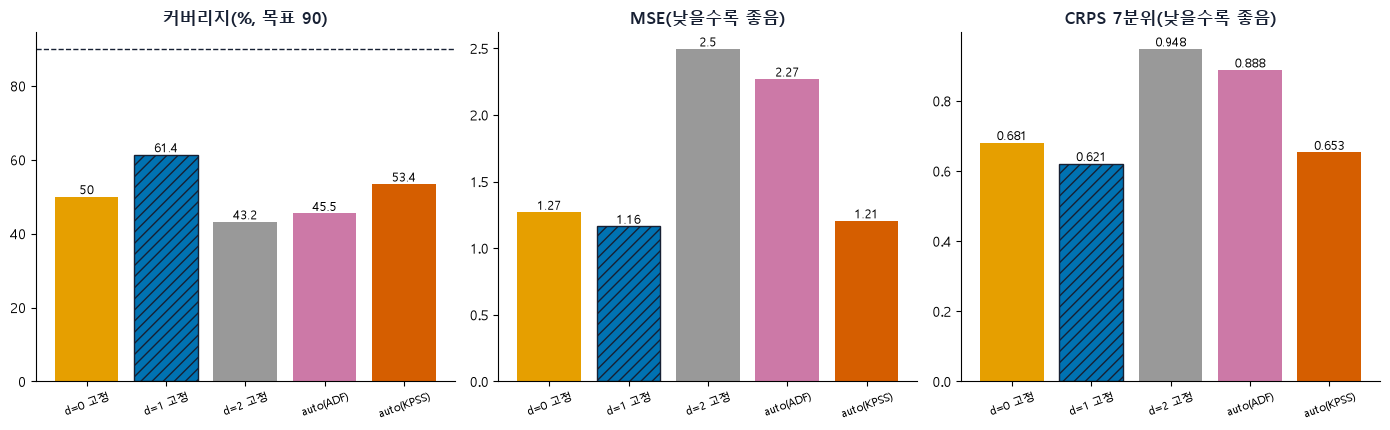

In [11]:
def run_auto(test):
    out = []
    for o in scored_origins:
        train, actual = vals[:o], vals[o:o + H]
        m = pm.auto_arima(train, seasonal=False, test=test, information_criterion="aicc", max_p=3, max_q=3,
                          suppress_warnings=True, error_action="ignore")
        fc, q7 = quantiles7(m)
        crps7 = 2 * np.mean([pinball(q7[k], actual, LEVELS[k]) for k in range(7)], axis=0) / var_std
        _, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
        out.append({"origin": o, "d": m.order[1], "order": m.order,
                    "커버리지": 100 * np.mean((actual >= conf[:, 0]) & (actual <= conf[:, 1])),
                    "MSE": np.mean(((actual - fc) / var_std) ** 2), "CRPS(7분위)": crps7.mean()})
    return pd.DataFrame(out).set_index("origin")


CACHE2 = "../cache/cache_91_auto_q7_df.pkl"
if os.path.exists(CACHE2):
    auto = pd.read_pickle(CACHE2)
else:
    auto = pd.concat({"auto(KPSS)": run_auto("kpss"), "auto(ADF)": run_auto("adf")}, names=["설정"])
    auto.to_pickle(CACHE2)

metrics3 = ["커버리지", "MSE", "CRPS(7분위)"]
summary2 = pd.concat([summary.rename(index={0: "d=0 고정", 1: "d=1 고정", 2: "d=2 고정"}),
                      auto.groupby("설정")[metrics3].mean().round(3)])
display(summary2)
print("자동 선택된 d의 분포 -- auto(KPSS):", auto.loc["auto(KPSS)"]["d"].value_counts().sort_index().to_dict(),
      " auto(ADF):", auto.loc["auto(ADF)"]["d"].value_counts().sort_index().to_dict())

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
colr2 = {"d=0 고정": "#E69F00", "d=1 고정": "#0072B2", "d=2 고정": "#999999", "auto(KPSS)": "#D55E00", "auto(ADF)": "#CC79A7"}
for ax, (c, t) in zip(axes, [("커버리지", "커버리지(%, 목표 90)"), ("MSE", "MSE(낮을수록 좋음)"), ("CRPS(7분위)", "CRPS 7분위(낮을수록 좋음)")]):
    bars = ax.bar(summary2.index, summary2[c], color=[colr2[i] for i in summary2.index])
    score = (summary2[c] - 90).abs() if c == "커버리지" else summary2[c]
    for b, k in zip(bars, summary2.index):
        if score[k] <= score.min() + 1e-9:   # 1등에 빗금
            b.set_hatch("///")
            b.set_edgecolor("#172033")
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.3g}", ha="center", va="bottom", fontsize=9)
    if c == "커버리지":
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.tick_params(axis="x", labelsize=8, rotation=20)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**결과**: 자동 선택은 d=1 고정보다 낫지 않다.

| 설정 | 커버리지(%) | MSE | CRPS(7분위) |
|---|---|---|---|
| d=1 고정 | 61.4 | 1.164 | 0.621 |
| auto(KPSS 기본) | 53.4 | 1.205 | 0.653 |
| auto(ADF) | 45.5 | 2.269 | 0.888 |

- **auto(KPSS)**: 22개 중 21개에서 d=0을 골라 d=1 고정보다 나쁘다(CRPS 0.653 vs 0.621).
- **auto(ADF)**: d=2를 12개, d=1을 7개, d=0을 3개 골라 d=0, 1, 2 고정 어느 쪽보다 불리하다(MSE 2.269). 과차분의 영향이 크다.
- 확인용이므로 결정에는 쓰지 않지만, 검정에 맡기는 것이 d=1 고정보다 나은 근거는 없다.

## 4. 결론

**d=1로 고정한다.**

- **자동 선택의 결과가 일관되지 않음(1절)**: 검정 결과가 origin마다 달라지고(KPSS는 20/22개가 상한 0.10, ADF는 d=2·1·0으로 널뜀, 두 검정 불일치 18/22), AIC·AICc로는 d를 비교할 수 없다.
- **데이터 특징으로 d=1(2절)**: 수준이 크게 출렁이고, 수준 ACF가 천천히 줄며(lag-1 0.89), 1차 차분하면 정상에 가깝다(lag-1 0.40). 전체 데이터에서는 KPSS·ADF도 d=1과 일치한다.
- **확인(3절, 결정에 쓰지 않음)**: d=1이 세 지표 모두 최선이었다.

| d | 커버리지(%) | MSE | CRPS(7분위) |
|---|---|---|---|
| 0 | 50.0 | 1.269 | 0.681 |
| 1 | 61.4 | 1.164 | 0.621 |
| 2 | 43.2 | 2.495 | 0.948 |

  d=1에서는 22개 중 17개가 (1,1,0)을 골랐다.
- **자동 선택과 비교(3-1절)**: auto_arima가 d를 고르게 하면 d=1 고정보다 나쁘다(auto(KPSS) CRPS 0.653, auto(ADF) 0.888 vs 0.621). 검정에 맡길 이유가 없다.
- **한계**: 전체 데이터(평가 구간 포함)로 정했고, 첫 35개만 쓰면 검정이 갈린다(KPSS d=0, ADF d=2). 이전 노트북(8-3)에서 d=1의 평가 결과가 좋다는 것을 이미 본 상태였다. 4분기 합이라 자기상관이 기계적으로 높다. 22개 origin이 겹쳐 유의성은 검증하지 않았다.

**다음 단계**: `9-2`에서 auto_arima가 p,q를 고른다(AIC vs AICc).